# Word-Match Highlight (Figure 5a generator)

Renders the manuscript's word-overlap panel for ANY benchmark question: the query, the
expert Ground Truth answer, and the T21 Research Assistant response side by side, with
every word shared between GT and the T21 answer highlighted in gold. Also prints the
lexical overlap stats and the adapted BERTScore of all four notebook-3 arms vs GT.

Fresh round 2026-09-06: reads notebook 3's
`output/ScientificReportRevisionV1/batch_eval/responses_latest.json`
(30 positive controls, generated on the 1,594-article corpus
DS_INCLUDE_2026_09_02_DEEPINFRA_2048, 65,677 vectors); scoring embeds via the
production `/embed_batch` endpoint (nvidia/llama-nemotron-embed-vl-1b-v2, 2048-dim).

Usage: set `KEYWORD` in the parameter cell to any distinctive phrase from the question
(e.g. "lower risk", "interferon receptors", "sleep apnea") and run all cells. Output:
`output/ScientificReportRevisionV1/word_match/word_match_<SLNo>_<slug>_600dpi.{jpg,pdf}`.


In [1]:
import json
import re
import os
import math
import requests
import numpy as np
from pathlib import Path
from IPython.display import display
from PIL import Image as PILImage, ImageDraw, ImageFont
import pandas as pd


In [2]:
# ── Load JSON responses ──────────────────────────────────────────────────────
DATA_PATH = Path("../output/ScientificReportRevisionV1/batch_eval/responses_latest.json")
with DATA_PATH.open() as f:
    data = json.load(f)

# ── Load benchmark Excel (kept for reference only) ────────────────────────────

# ── Record lookup ─────────────────────────────────────────────────────────────
def get_record(keyword: str) -> dict:
    rec = next(
        (r for r in data["responses"]
         if keyword.strip().lower() in r["question"].strip().lower()),
        None,
    )
    if rec is None:
        raise ValueError(f"Question not found for keyword: {keyword!r}")
    return rec

# ── Nemotron-8B BERTScore — exact match to notebook 3 (/embed_batch API) ──────
# Mirrors _split_sents_sc / _embed_batch_sc / _bertscore_sc from
# 3_benchmark_pipeline_vs_ground_truth.ipynb (shortcut loading cell).
EMBED_API  = "http://localhost:8698/embed_batch"
MODEL_FIELDS = {
    "T21 RAG":  "t21_answer",
    "GPT":      "gpt_answer",
    "Claude":   "claude_answer",
    "Nemotron": "nemotron_answer",
}

_SENT_RE = re.compile(r"(?<=[.!?])\s+")
_SEMI_RE = re.compile(r"\s*;\s*")

def _split_sents(text: str) -> list:
    """Sentence splitter identical to notebook 3's _split_sents_sc:
    split on .!? first; then split further on ; for clauses without terminal .!?"""
    raw = _SENT_RE.split(str(text or "").strip())
    result = []
    for chunk in raw:
        chunk = chunk.strip()
        if not chunk:
            continue
        if ";" in chunk and not re.search(r"[.!?]\s*$", chunk):
            parts = [p.strip() for p in _SEMI_RE.split(chunk) if p.strip()]
            result.extend(parts)
        else:
            result.append(chunk)
    return result

def _embed_batch(texts: list) -> np.ndarray:
    """POST to /embed_batch -> nvidia/llama-nemotron-embed-vl-1b-v2, 2048-dim (DeepInfra)."""
    r = requests.post(EMBED_API, json={"texts": texts, "mode": "document"}, timeout=180)
    r.raise_for_status()
    return np.array(r.json()["embeddings"], dtype=np.float32)

def _bertscore(ref_text: str, cand_text: str) -> dict:
    """BERTScore (P/R/F) + doc-level cosine sim — identical algorithm to notebook 3."""
    _default = {"P": 0.0, "R": 0.0, "F1": 0.0, "Sim": 0.0}
    ref_sents  = _split_sents(ref_text)
    cand_sents = _split_sents(cand_text)
    if not ref_sents or not cand_sents:
        return _default
    try:
        # Embed sentences + full documents in one batched call
        all_texts = ref_sents + cand_sents + [ref_text, cand_text]
        vecs = _embed_batch(all_texts)
        nr, nc = len(ref_sents), len(cand_sents)

        # Sentence-level BERTScore (L2-normalise then dot product = cosine)
        sent_vecs = vecs[:nr + nc]
        norms = np.linalg.norm(sent_vecs, axis=1, keepdims=True)
        sent_vecs = sent_vecs / np.maximum(norms, 1e-9)
        sim = sent_vecs[:nr] @ sent_vecs[nr:].T          # [ref x cand]
        recall    = float(sim.max(axis=1).mean())         # each ref -> best cand
        precision = float(sim.max(axis=0).mean())         # each cand -> best ref
        f1 = 2*precision*recall / (precision+recall) if (precision+recall) > 0 else 0.0

        # Document-level cosine similarity
        ref_doc, cand_doc = vecs[nr+nc], vecs[nr+nc+1]
        d = np.linalg.norm(ref_doc) * np.linalg.norm(cand_doc)
        sim_doc = float(np.dot(ref_doc, cand_doc) / d) if d > 0 else 0.0

        return {"P": round(precision, 4), "R": round(recall, 4),
                "F1": round(f1, 4), "Sim": round(sim_doc, 4)}
    except Exception as exc:
        print(f"  [bertscore_err] {exc}")
        return {k: float("nan") for k in _default}

def get_scores_nemotron(keyword: str) -> dict:
    """Compute Nemotron-8B BERTScore for all 4 models vs Ground Truth
    (same algorithm as notebook 3's shortcut loading cell)."""
    rec = get_record(keyword)
    gt  = rec["ground_truth"].strip()
    print(f"Computing BERTScore via /embed_batch  [nvidia/llama-nemotron-embed-vl-1b-v2, 2048-dim (DeepInfra)]")
    scores = {}
    for model, field in MODEL_FIELDS.items():
        cand = rec.get(field, "").strip()
        if not cand:
            scores[model] = {"P": 0.0, "R": 0.0, "F1": 0.0, "Sim": 0.0}
            continue
        print(f"  {model:<10} ...", end=" ", flush=True)
        scores[model] = _bertscore(gt, cand)
        s = scores[model]
        print(f"P={s['P']:.4f}  R={s['R']:.4f}  F1={s['F1']:.4f}  Sim={s['Sim']:.4f}")
    return scores

print(f"JSON loaded  : {len(data['responses'])} questions")
print(f"Embed API    : {EMBED_API}  [nvidia/llama-nemotron-embed-vl-1b-v2, 2048-dim (DeepInfra)]")
print(f"Algorithm    : matches notebook 3 (3_benchmark_pipeline_vs_ground_truth.ipynb)")


JSON loaded  : 30 questions
Embed API    : http://localhost:8698/embed_batch  [nvidia/llama-nemotron-embed-vl-1b-v2, 2048-dim (DeepInfra)]
Algorithm    : matches notebook 3 (3_benchmark_pipeline_vs_ground_truth.ipynb)


In [3]:
# ── Canvas & font setup ───────────────────────────────────────────────────────
DPI    = 600
FIG_W  = int(6.83 * DPI)   # 6.83 inch wide
MARGIN = int(0.45 * DPI)
TEXT_W = FIG_W - 2 * MARGIN

def _font(pt, bold=False):
    px  = int(pt * DPI / 72)
    sfx = "-Bold" if bold else ""
    for p in [
        f"/usr/share/fonts/truetype/dejavu/DejaVuSans{sfx}.ttf",
        f"/usr/share/fonts/truetype/liberation/LiberationSans{sfx}.ttf",
        f"/usr/share/fonts/truetype/ubuntu/Ubuntu{'-B' if bold else '-R'}.ttf",
    ]:
        if os.path.exists(p):
            return ImageFont.truetype(p, px)
    return ImageFont.load_default()

FT      = _font(11)          # body
FTB     = _font(11, True)    # body bold
FH      = _font(12, True)    # section header
FTITLE  = _font(13, True)    # title
FS      = _font(9)           # small / caption

_probe  = ImageDraw.Draw(PILImage.new("RGB", (1, 1)))
tw  = lambda s, f=FT:  (_probe.textbbox((0,0), s, font=f)[2] - _probe.textbbox((0,0), s, font=f)[0])
th  = lambda f=FT:     (_probe.textbbox((0,0), "Ag", font=f)[3] - _probe.textbbox((0,0), "Ag", font=f)[1])

LH   = int(th(FT) * 1.45)   # line height (tight)
GAP  = int(0.10 * DPI)       # section gap

NAVY   = (44,  82, 130)       # title bar  — mid-dark blue
WHITE  = (255, 255, 255)
# section headers: soft tinted backgrounds, dark text
GT_BG  = (220, 240, 220)      # light sage green
GT_TXT = (28,  90,  28)       # dark green text
T21_BG = (215, 230, 250)      # light periwinkle blue
T21_TXT= (30,  70, 150)       # dark blue text
GOLD   = (255, 220,  50)
DARK   = (30,  30,  30)
GRAY   = (110, 110, 110)

# keep old names as aliases so _header_bar still works
GREEN  = GT_BG
BLUE   = T21_BG

print(f"Canvas: {FIG_W} x auto px @ {DPI} DPI  ({FIG_W/DPI:.2f}\")")  


Canvas: 4098 x auto px @ 600 DPI  (6.83")


In [4]:
# ── Tokenizer ────────────────────────────────────────────────────────────────
STOPWORDS = {
    "the", "a", "an", "in", "of", "and", "or", "to", "for", "is", "are",
    "that", "this", "with", "on", "at", "by", "as", "it", "its", "be",
    "was", "were", "has", "have", "had", "from", "not", "but", "also",
    "their", "they", "which", "who", "what", "how", "when", "where",
    "both", "each", "all", "any", "been", "into", "than", "such",
    "these", "those", "thus", "via", "while", "about", "through",
}

def tokenize(text: str) -> set:
    tokens = re.findall(r"[A-Za-z][A-Za-z0-9_-]*", text)
    return {t.lower() for t in tokens if len(t) >= 2 and t.lower() not in STOPWORDS}

def overlap_stats(gt_text: str, t21_text: str) -> tuple:
    """Return (shared, precision, recall, f1)."""
    gt_tok  = tokenize(gt_text)
    t21_tok = tokenize(t21_text)
    shared  = gt_tok & t21_tok
    p = len(shared) / len(t21_tok) if t21_tok else 0
    r = len(shared) / len(gt_tok)  if gt_tok  else 0
    f = 2*p*r/(p+r) if (p+r) else 0
    return shared, p, r, f

print("Tokenizer and overlap_stats() defined.")


Tokenizer and overlap_stats() defined.


In [5]:
# ── Figure helpers ────────────────────────────────────────────────────────────

def _wrap_draw(d, y, text, shared, font=FT, font_bold=FTB):
    """Draw word-wrapped text; gold background on shared words."""
    x = MARGIN
    for tok in re.split(r"(\s+)", text):
        if not tok:
            continue
        if tok.isspace():
            x += tw(" ", font)
            continue
        w = tw(tok, font)
        if x + w > MARGIN + TEXT_W:
            x = MARGIN
            y += LH
        key = re.sub(r"[^a-z0-9]", "", tok.lower())
        if len(key) > 1 and key in shared:
            pad = 4
            d.rectangle([x-pad, y-2, x+w+pad, y+th(font)+2], fill=GOLD)
        d.text((x, y), tok, font=font, fill=DARK)
        x += w
    return y + LH

def _header_bar(d, y, label, color):
    txt_color = GT_TXT if color == GREEN else T21_TXT
    h = int(th(FH) * 2.0)
    d.rectangle([MARGIN, y, MARGIN+TEXT_W, y+h], fill=color)
    d.text((MARGIN + int(0.08*DPI), y + (h - th(FH))//2), label, font=FH, fill=txt_color)
    return y + h + int(0.08*DPI)

def build_figure(question_, gt_text_, t21_text_, shared_):
    # Estimate canvas height
    canvas_h = int(12 * DPI)
    img = PILImage.new("RGB", (FIG_W, canvas_h), WHITE)
    d   = ImageDraw.Draw(img)

    y = int(0.14*DPI)

    # ── Query ────────────────────────────────────────────────────────────────
    d.text((MARGIN, y), "Query:", font=FTB, fill=NAVY)
    y += th(FTB) + int(0.03*DPI)
    y = _wrap_draw(d, y, question_, set(), font=FT) + int(0.12*DPI)

    # ── Ground Truth ─────────────────────────────────────────────────────────
    y = _header_bar(d, y, "GROUND TRUTH", GREEN)
    y = _wrap_draw(d, y, gt_text_, shared_) + GAP

    # ── T21 Response ─────────────────────────────────────────────────────────
    y = _header_bar(d, y, "T21 RESEARCH ASSISTANT RESPONSE", BLUE)
    y = _wrap_draw(d, y, t21_text_, shared_) + GAP

    # ── Legend ───────────────────────────────────────────────────────────────
    pad = 5
    lbl = "  Highlighted  "
    lw  = tw(lbl, FTB)
    lh  = th(FT)
    d.rectangle([MARGIN-pad, y-2, MARGIN+lw+pad, y+lh+2], fill=GOLD)
    d.text((MARGIN, y), lbl, font=FTB, fill=DARK)
    d.text((MARGIN + lw + pad + int(0.06*DPI), y),
           "= word appears in both Ground Truth and T21 Response",
           font=FS, fill=GRAY)
    y += lh + int(0.14*DPI)

    return img.crop((0, 0, FIG_W, y))

def save_figure(fig, stem):
    OUT = Path("../output/ScientificReportRevisionV1/word_match")
    OUT.mkdir(parents=True, exist_ok=True)
    _rs = PILImage.Resampling.LANCZOS if hasattr(PILImage, "Resampling") else PILImage.LANCZOS
    jpg = OUT / f"{stem}.jpg"
    pdf = OUT / f"{stem}.pdf"
    fig.save(str(jpg), "JPEG", quality=95, dpi=(DPI, DPI))
    fig.save(str(pdf), "PDF",  resolution=DPI)
    print(f"JPEG saved: {jpg.resolve()}")
    print(f"PDF  saved: {pdf.resolve()}")
    print(f"Size : {fig.width}x{fig.height} px  ({fig.width/DPI:.2f}\" x {fig.height/DPI:.2f}\")")  
    display(fig.resize((fig.width//4, fig.height//4), _rs))

print("build_figure() and save_figure() ready.")


build_figure() and save_figure() ready.


In [6]:
# ── PARAMETER: pick the question by any distinctive keyword/phrase ────────────
KEYWORD = "Stat1"   # Q7, T21 best-vs-all-arms question; e.g. "lower risk", "blood pressure"

rec      = get_record(KEYWORD)
question = rec["question"].strip()
gt       = rec["ground_truth"].strip()
t21      = rec["t21_answer"].strip()
sl_no    = str(rec.get("sl_no", "Q")).strip()
scores   = get_scores_nemotron(KEYWORD)
shared, p_, r_, f1_ = overlap_stats(gt, t21)

print(f"\n{sl_no}: {question}\n")
print(f"Shared tokens: {len(shared)}  |  Precision: {p_:.1%}  |  Recall: {r_:.1%}  |  F1: {f1_:.1%}")
print(f"Shared words : {', '.join(sorted(shared))}")
print(f"\n{'Model':<12}  {'BertP':>7}  {'BertR':>7}  {'BertF1':>7}  {'SemanticSim':>12}")
print("-" * 56)
for mdl, sc in scores.items():
    mk = " <--" if mdl == "T21 RAG" else ""
    print(f"{mdl:<12}  {sc['P']:>7.4f}  {sc['R']:>7.4f}  {sc['F1']:>7.4f}  {sc['Sim']:>12.4f}{mk}")


Computing BERTScore via /embed_batch  [nvidia/llama-nemotron-embed-vl-1b-v2, 2048-dim (DeepInfra)]
  T21 RAG    ... 

P=0.5700  R=0.6857  F1=0.6225  Sim=0.5815
  GPT        ... 

P=0.5876  R=0.5876  F1=0.5876  Sim=0.5877
  Claude     ... 

P=0.5849  R=0.5849  F1=0.5849  Sim=0.5849
  Nemotron   ... 

P=0.5357  R=0.5357  F1=0.5357  Sim=0.5357

7: How is Stat1 signaling affected in Down syndrome?

Shared tokens: 6  |  Precision: 15.4%  |  Recall: 50.0%  |  F1: 23.5%
Shared words : due, increased, interferon, overexpression, signaling, stat1

Model           BertP    BertR   BertF1   SemanticSim
--------------------------------------------------------
T21 RAG        0.5700   0.6857   0.6225        0.5815 <--
GPT            0.5876   0.5876   0.5876        0.5877
Claude         0.5849   0.5849   0.5849        0.5849
Nemotron       0.5357   0.5357   0.5357        0.5357


JPEG saved: /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/word_match/word_match_7_stat1_600dpi.jpg
PDF  saved: /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/word_match/word_match_7_stat1_600dpi.pdf
Size : 4098x2378 px  (6.83" x 3.96")


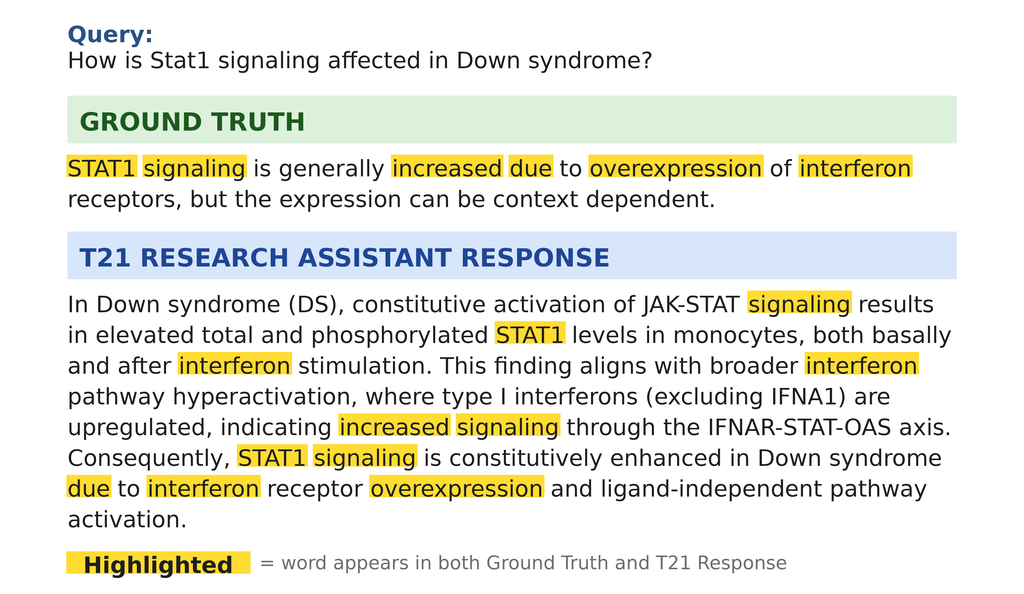

In [7]:
# ── Export 600 DPI JPEG + PDF ─────────────────────────────────────────────────
fig = build_figure(question, gt, t21, shared)
_slug = re.sub(r"[^A-Za-z0-9]+", "_", KEYWORD.strip().lower()).strip("_")
save_figure(fig, f"word_match_{sl_no}_{_slug}_600dpi")
